# 可选实验：模型表示

<figure>
 <img src="./images/C1_W1_L3_S1_Lecture_b.png"   style="width:600px;height:200px;">
</figure>

## 学习目标
在本实验中，你会：
- 学会实现单变量线性回归模型 $f_{w,b}$

## 符号说明
以下是你将遇到的一些符号的摘要。

| 通用 <br /> 符号 | 说明 | Python（如适用） |
|:------------------------|:-------------------------------------------|:---------------------|
| $a$ | 标量，非粗体 | |
| $\mathbf{a}$ | 向量，粗体 | |
| **回归** | | |
| $\mathbf{x}$ | 训练样本的特征值（本实验中为房屋面积，单位 1000 平方英尺） | `x_train` |
| $\mathbf{y}$ | 训练样本的目标值（本实验中为房价，单位 1000 美元） | `y_train` |
| $x^{(i)}$、$y^{(i)}$ | 第 $i$ 个训练样本 | `x_i`、`y_i` |
| m | 训练样本数量 | `m` |
| $w$ | 参数：权重 | `w` |
| $b$ | 参数：偏置 | `b` |
| $f_{w,b}(x^{(i)})$ | 模型在 $x^{(i)}$ 处、由 $w,b$ 参数化的预测结果：$f_{w,b}(x^{(i)}) = wx^{(i)}+b$ | `f_wb` |

## 工具
在本实验中你将使用：
- NumPy，一个流行的科学计算库
- Matplotlib，一个常用的数据绘图库

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')

# 问题描述
<img align="left" src="./images/C1_W1_L3_S1_trainingdata.png"    style=" width:380px; padding: 10px;  " />

与讲座中一样，你将使用房价预测这一示例。
本实验使用一个仅含两个数据点的简单数据集——一套 1000 平方英尺（sqft）的房屋售价 \\$300,000，另一套 2000 平方英尺的房屋售价 \\$500,000。这两个点构成我们的*数据或训练集*。在本实验中，面积的单位为 1000 平方英尺，价格的单位为 1000 美元。

| 面积（1000 平方英尺）     | 价格（1000 美元） |
| -------------------| ------------------------ |
| 1.0               | 300                      |
| 2.0               | 500                      |

你希望通过这两个点拟合一个线性回归模型（上图中蓝色的直线），以便预测其他房屋的价格——例如一套 1200 平方英尺的房屋。

请运行下面的代码单元格，创建 `x_train` 和 `y_train` 变量。数据存储在一维 NumPy 数组中。

In [2]:
# x_train is the input variable (size in 1000 square feet)
# y_train is the target (price in 1000s of dollars)
x_train = np.array([1.0, 2.0])
y_train = np.array([300.0, 500.0])
print(f"x_train = {x_train}")
print(f"y_train = {y_train}")

x_train = [1. 2.]
y_train = [300. 500.]


>**说明**：本课程在打印输出时会频繁使用 Python 的 'f-string' 输出格式化，详见[此处](https://docs.python.org/3/tutorial/inputoutput.html)。花括号中的内容会在生成输出时被求值。

### 训练样本数量 `m`
你将用 `m` 表示训练样本的数量。NumPy 数组有一个 `.shape` 参数。`x_train.shape` 返回一个 Python 元组，其中每一项对应一个维度。`x_train.shape[0]` 即为数组的长度，也就是样本数量，如下所示。

In [3]:
# m is the number of training examples
print(f"x_train.shape: {x_train.shape}")
m = x_train.shape[0]
print(f"Number of training examples is: {m}")

x_train.shape: (2,)
Number of training examples is: 2


也可以使用 Python 的 `len()` 函数，如下所示。

In [4]:
# m is the number of training examples
m = len(x_train)
print(f"Number of training examples is: {m}")

Number of training examples is: 2


### 训练样本 `x_i, y_i`

你将用 (x$^{(i)}$, y$^{(i)}$) 表示第 $i$ 个训练样本。由于 Python 的索引从 0 开始，(x$^{(0)}$, y$^{(0)}$) 为 (1.0, 300.0)，(x$^{(1)}$, y$^{(1)}$) 为 (2.0, 500.0)。

要访问 NumPy 数组中的某个值，需要用所需的偏移量对数组进行索引。例如，访问 `x_train` 中第 0 个位置的语法是 `x_train[0]`。
运行下面的代码块，获取第 $i$ 个训练样本。

In [5]:
i = 0 # Change this to 1 to see (x^1, y^1)

x_i = x_train[i]
y_i = y_train[i]
print(f"(x^({i}), y^({i})) = ({x_i}, {y_i})")

(x^(0), y^(0)) = (1.0, 300.0)


### 绘制数据

你可以使用 `matplotlib` 库中的 `scatter()` 函数绘制这两个点，如下面的单元格所示。
- 函数参数 `marker` 和 `c` 会将这些点显示为红色叉号（默认为蓝色圆点）。

你还可以使用 `matplotlib` 库中的其他函数来设置要显示的标题和坐标轴标签。

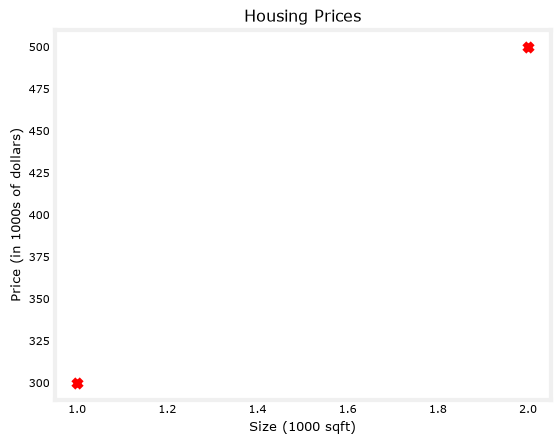

In [6]:
# Plot the data points
plt.scatter(x_train, y_train, marker='x', c='r')
# Set the title
plt.title("Housing Prices")
# Set the y-axis label
plt.ylabel('Price (in 1000s of dollars)')
# Set the x-axis label
plt.xlabel('Size (1000 sqft)')
plt.show()

## 模型函数

<img align="left" src="./images/C1_W1_L3_S1_model.png"     style=" width:380px; padding: 10px; " > 如讲座中所述，线性回归的模型函数（一个从 `x` 映射到 `y` 的函数）表示为

$$ f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{1}$$

上面的公式描述了如何表示直线——不同的 $w$ 和 $b$ 值会在图上给出不同的直线。<br/> <br/> <br/> <br/> <br/>

让我们通过下面的代码块来更好地理解这一点。先从 $w = 100$、$b = 100$ 开始。

**注意：你可以返回此单元格来调整模型的 w 和 b 参数**

In [7]:
w = 100
b = 100
print(f"w: {w}")
print(f"b: {b}")

w: 100
b: 100


现在，让我们为你的两个数据点计算 $f_{w,b}(x^{(i)})$ 的值。你可以为每个数据点显式地写出计算式——

对于 $x^{(0)}$，`f_wb = w * x[0] + b`

对于 $x^{(1)}$，`f_wb = w * x[1] + b`

当数据点数量很大时，这样写会变得繁琐且重复。因此，你可以像下面的 `compute_model_output` 函数那样，在 `for` 循环中计算函数输出。
> **说明**：参数描述 `(ndarray (m,))` 表示形状为 (m,) 的 NumPy n 维数组。`(scalar)` 表示没有维度、只有大小的标量参数。
> **说明**：`np.zero(n)` 会返回一个包含 $n$ 个元素的一维 NumPy 数组。

In [8]:
def compute_model_output(x, w, b):
    """
    Computes the prediction of a linear model
    Args:
      x (ndarray (m,)): Data, m examples 
      w,b (scalar)    : model parameters  
    Returns
      y (ndarray (m,)): target values
    """
    m = x.shape[0]
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w * x[i] + b
        
    return f_wb

现在让我们调用 `compute_model_output` 函数并绘制输出。

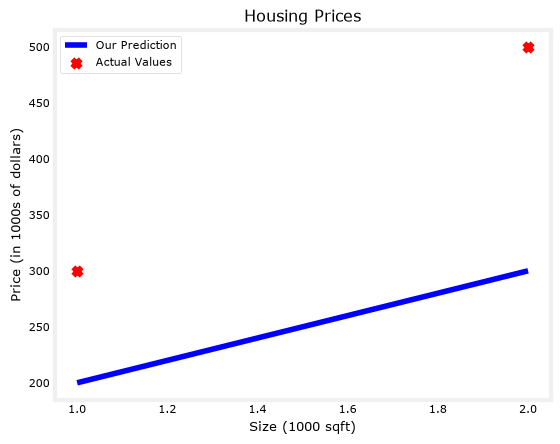

In [9]:
tmp_f_wb = compute_model_output(x_train, w, b,)

# Plot our model prediction
plt.plot(x_train, tmp_f_wb, c='b',label='Our Prediction')

# Plot the data points
plt.scatter(x_train, y_train, marker='x', c='r',label='Actual Values')

# Set the title
plt.title("Housing Prices")
# Set the y-axis label
plt.ylabel('Price (in 1000s of dollars)')
# Set the x-axis label
plt.xlabel('Size (1000 sqft)')
plt.legend()
plt.show()

可以看到，设置 $w = 100$、$b = 100$ *并不能*得到一条拟合我们数据的直线。

### 挑战
尝试使用不同的 $w$ 和 $b$ 值。要使直线拟合我们的数据，这些值应该是多少？

#### 提示：
你可以用鼠标点击下面绿色的 "Hints"，以获取一些关于选择 b 和 w 的提示。

<details>
<summary>
    <font size='3' color='darkgreen'><b>提示</b></font>
</summary>
    <p>
    <ul>
        <li>尝试 $w = 200$、$b = 100$ </li>
    </ul>
    </p>
</details>

### 预测
现在我们有了模型，就可以用它来进行最初的预测。让我们预测一套 1200 平方英尺房屋的价格。由于 $x$ 的单位是 1000 平方英尺，因此 $x$ 为 1.2。

In [10]:
w = 200                         
b = 100    
x_i = 1.2
cost_1200sqft = w * x_i + b    

print(f"${cost_1200sqft:.0f} thousand dollars")

$340 thousand dollars


# 恭喜完成！
在本实验中你已经学会了：
 - 线性回归构建一个模型，用以建立特征与目标值之间的关系
     - 在上面的例子中，特征是房屋面积，目标值是房价
     - 对于简单线性回归，模型有两个参数 $w$ 和 $b$，其值通过*训练数据*拟合得到
     - 一旦模型的参数确定，就可以用该模型对新数据进行预测